# Classification Models

## Discussion questions

Suppose you are developing a classification model to determine whether or not a person has a particular disease (based on symptoms, results of diagnostic tests, family history, risk factors, etc).

1. Explain what "precision" represents in this context.

Precision tells us how often the model is right when it says someone has the disease. Out of all the people the model says are sick, it’s the share who really are sick. For example, if the model says 100 people are sick and 80 really are, precision is 80%.


2. Explain what "recall" represents in this context.

Recall tells us how many of the truly sick people the model finds. Out of all the people who really have the disease, it’s the share the model catches. For example, if 100 people are really sick and the model finds 90 of them, recall is 90%.

3. Which of the following do you think is a more serious error? It's an opinion question, but choose one and discuss.

- Concluding that a person has the disease if they actually don't have it
- Failing to conclude that a person has the disease if they actually do have it

We think missing someone who really has the disease is worse. That person won’t get treatment, they could get sicker, and if the disease spreads they could pass it to others. Telling a healthy person they’re sick is also bad, because it causes worry and extra tests. But a follow-up test can usually catch that mistake, while a missed case often goes home with no more checks.

4. Given your answer to the previous question, which would you prefer to be higher: precision or recall?

We would want recall to be higher, because recall measures how well the model avoids missing sick people.

5. Suppose you want to achieve higher recall. Should your classification rule be more or less strict about who it predicts to have the disease?

Less strict. If the model needs less evidence before saying “this person has the disease,” it will catch more of the truly sick people, and recall goes up.

6. What is a downside to your choice in the previous part?

Being less strict means more healthy people get wrongly told they might be sick, so precision goes down. Those people may feel stressed and go through extra tests or treatment they didn’t need.

In [15]:
import pandas as pd
import numpy as np

## More wine

The wines data set (https://dlsun.github.io/pods/data/wines.csv ) contains data about the chemical composition of various wines. We'll first use just two features&mdash;fixed acidity and volatile acidity&mdash;to predict the color of the wine (red or white).

In [16]:
df_train = pd.read_csv("https://dlsun.github.io/pods/data/wines.csv")

df_train

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white


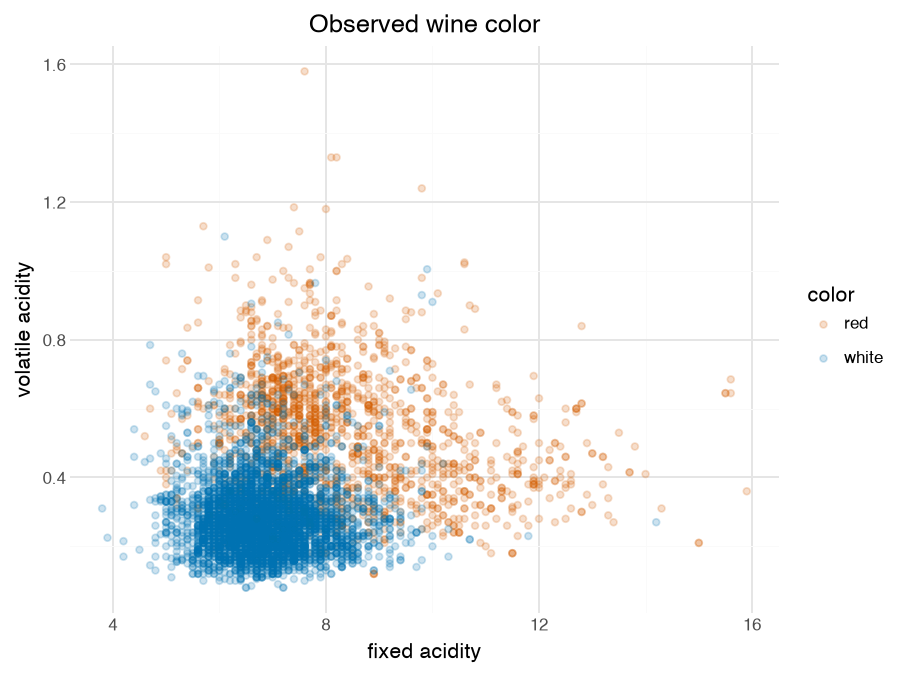

In [17]:
from plotnine import *

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Observed wine color")
    + theme_minimal()
)

1\. Fit a 15-nearest neighbors model for predicting color from fixed acidity and volatile acidity. Don't forget to scale the features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the observed colors.

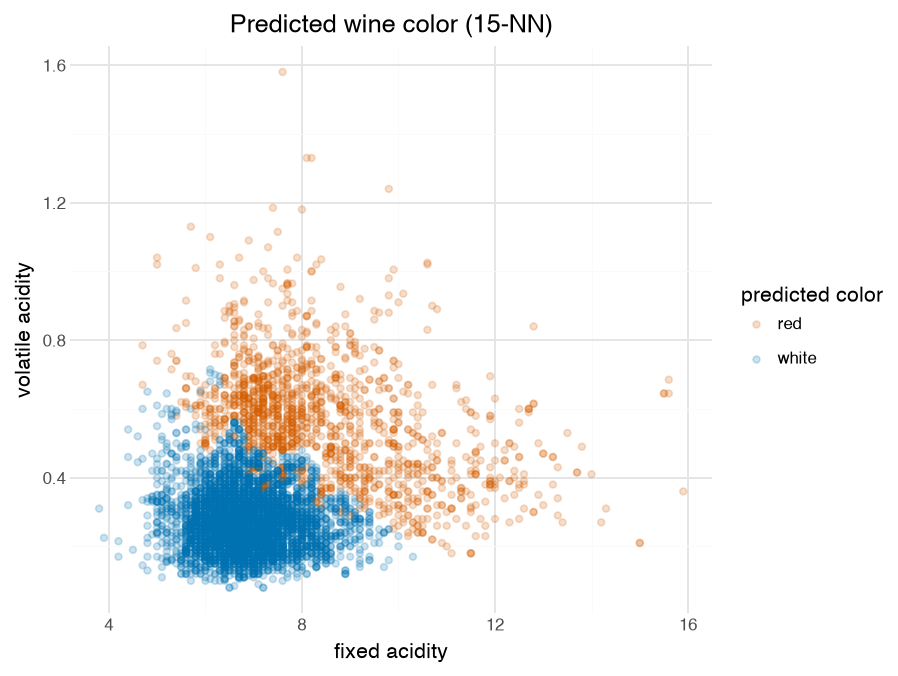

In [18]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

features = ["fixed acidity", "volatile acidity"]
X_train = df_train[features]
y_train = df_train["color"]

# Scale the features, then fit 15-nearest neighbors
pipeline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15)
)
pipeline.fit(X_train, y_train)

df_train["knn_pred"] = pipeline.predict(X_train)

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="knn_pred"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color (15-NN)", color="predicted color")
    + theme_minimal()
)

The predicted colors match the observed ones well: white wines are in the bottom-left and red wines are higher and to the right. The main difference is that the predicted plot has a cleaner split, while the real plot has red and white mixed together in the middle, so the model gets some of those overlapping wines wrong.

2\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score using `macro` scoring.

In [19]:
from sklearn.model_selection import cross_val_score

knn_scores = {}
for metric in ["precision_macro", "recall_macro", "f1_macro"]:
    knn_scores[metric] = cross_val_score(
        pipeline, X_train, y_train, cv=10, scoring=metric
    ).mean()

knn_scores

{'precision_macro': np.float64(0.8813805542523216),
 'recall_macro': np.float64(0.8543688286606457),
 'f1_macro': np.float64(0.8632968326738716)}

3\. Use `GridSearchCV` to fit $k$-nearest neighbors models for $k=1,\ldots, 30$ and use cross validation to estimate the test F1 macro score. Plot the test score versus $k$. Which value of $k$ yields the best score?

The best value is k = 16, with a cross-validated F1 (macro) score of about 0.866.

Best k: 16
Best CV F1 (macro): 0.8664272356440673


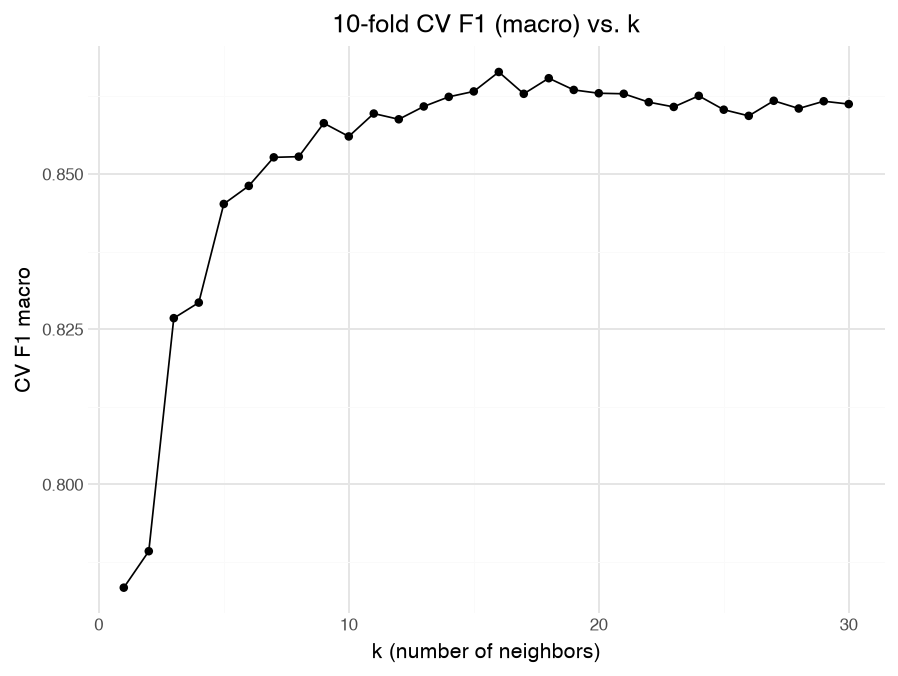

In [20]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsClassifier()),
    param_grid={"kneighborsclassifier__n_neighbors": range(1, 31)},
    scoring="f1_macro",
    cv=10
)
grid_search.fit(X_train, y_train)

df_k = pd.DataFrame({
    "k": range(1, 31),
    "f1_macro": grid_search.cv_results_["mean_test_score"]
})

print("Best k:", grid_search.best_params_["kneighborsclassifier__n_neighbors"])
print("Best CV F1 (macro):", grid_search.best_score_)

(
    ggplot(df_k, aes(x="k", y="f1_macro"))
    + geom_line()
    + geom_point()
    + labs(title="10-fold CV F1 (macro) vs. k", x="k (number of neighbors)", y="CV F1 macro")
    + theme_minimal()
)

4\. When the target variable is binary **logistic regression** provides another classification algorithm.

Fit a logistic regression model for predicting wine color from the two features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the predictions from the nearest neighbors classifier.

Note: with regression, you don't need to scale the features (unless you add a penalty). Hint: you basically just need to replace with `KNeighborsClassifier()` with `LogisticRegression()`.

Both models split the wines in a similar way: white wines in the bottom-left and red wines higher up and to the right. The big difference is the shape of the border between the two colors. Logistic regression draws a straight diagonal line, going down from upper-left to lower-right around fixed acidity 6–10 and volatile acidity 0.3–0.6. Every wine on one side is called white and every wine on the other side is called red. The 15-nearest neighbors border is bumpy and uneven, because it follows small local groups of points. For example, KNN called some wines with fixed acidity near 6 and volatile acidity up to about 0.7 white, but logistic regression called most of those red. Logistic regression gives a simpler, smoother rule, while KNN is more flexible.

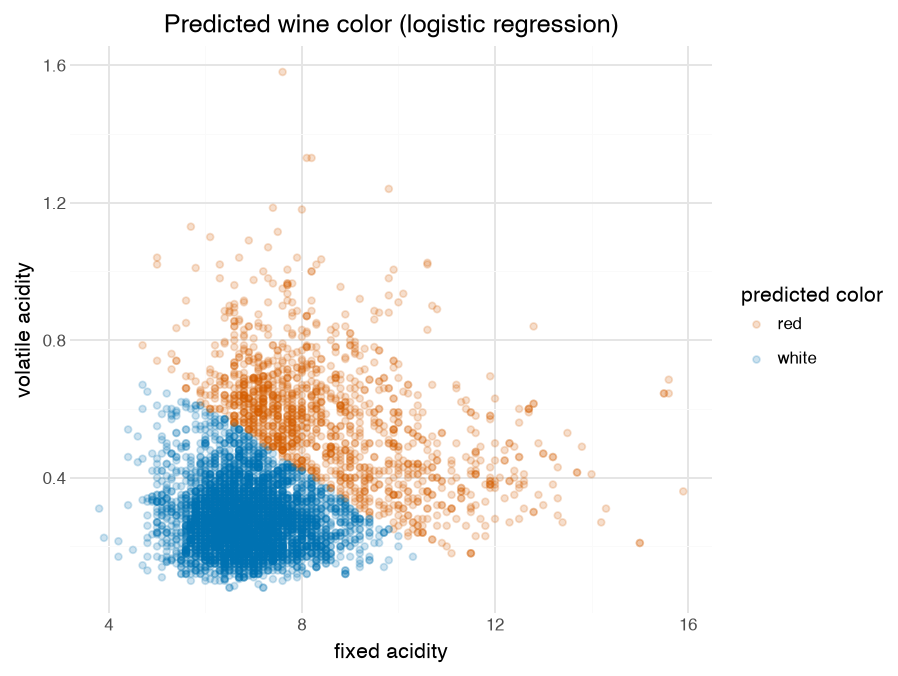

In [21]:
from sklearn.linear_model import LogisticRegression

logit_model = LogisticRegression()
logit_model.fit(X_train, y_train)

df_train["logit_pred"] = logit_model.predict(X_train)

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="logit_pred"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color (logistic regression)", color="predicted color")
    + theme_minimal()
)

5\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring. Compare to the nearest neighbors model.

The two models perform almost the same. Logistic regression has slightly higher precision (0.893 vs 0.881), but 15-NN has slightly higher recall (0.854 vs 0.845) and F1 (0.863 vs 0.860). The differences are very small, so neither model is clearly better.

In [22]:
logit_scores = {}
for metric in ["precision_macro", "recall_macro", "f1_macro"]:
    logit_scores[metric] = cross_val_score(
        LogisticRegression(), X_train, y_train, cv=10, scoring=metric
    ).mean()

pd.DataFrame({"15-NN": knn_scores, "Logistic (2 features)": logit_scores})

,15-NN,Logistic (2 features)
precision_macro,0.881381,0.892620
recall_macro,0.854369,0.845064
f1_macro,0.863297,0.860420


6\. Now fit a logistic regression model using all of the potential predictors. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [23]:
X_all = df_train.drop(columns=["color", "knn_pred", "logit_pred"])

logit_all = LogisticRegression(max_iter=10000)

logit_all_scores = {}
for metric in ["precision_macro", "recall_macro", "f1_macro"]:
    logit_all_scores[metric] = cross_val_score(
        logit_all, X_all, y_train, cv=10, scoring=metric
    ).mean()

logit_all_scores

{'precision_macro': np.float64(0.9840426944628378),
 'recall_macro': np.float64(0.9760806534675451),
 'f1_macro': np.float64(0.9798652063011044)}

7\. Now fit a logistic regression model using all of the potential predictors with a LASSO (`"l1"`) penalty. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [24]:
import warnings
warnings.filterwarnings("ignore")

lasso_logit = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty="l1", solver="liblinear")
)

lasso_scores = {}
for metric in ["precision_macro", "recall_macro", "f1_macro"]:
    lasso_scores[metric] = cross_val_score(
        lasso_logit, X_all, y_train, cv=10, scoring=metric
    ).mean()

pd.DataFrame({
    "15-NN (2 features)": knn_scores,
    "Logistic (2 features)": logit_scores,
    "Logistic (all features)": logit_all_scores,
    "Logistic LASSO (all features)": lasso_scores,
})

,15-NN (2 features),Logistic (2 features),Logistic (all features),Logistic LASSO (all features)
precision_macro,0.881381,0.892620,0.984043,0.992360
recall_macro,0.854369,0.845064,0.976081,0.991074
f1_macro,0.863297,0.860420,0.979865,0.991690


Using all the predictors helps a lot. Logistic regression goes from an F1 of about 0.86 with two features to 0.98 with all features, and the LASSO version is the best at about 0.99 for precision, recall, and F1.